# 0. Setup

In [2]:
import os, sys, subprocess, glob
import os.path as op

notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
# utils.py lives one folder up, so:
sys.path.append(parent_dir)

from utils import loadFSL, FSLeyesServer

import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
loadFSL()

from fsl.wrappers import fast, flirt, fslroi, mcflirt
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from nilearn.glm.first_level import make_first_level_design_matrix

## Starting FSL

In [4]:
%gui wx


(ipykernel_launcher.py:13959): dbind-WARNING **: 07:23:16.791: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/911264669/at-spi/bus_100: No such file or directory


In [5]:
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

07:23:18: Debug: Adding duplicate image handler for 'Windows bitmap file'
07:23:18: Debug: Adding duplicate animation handler for '1' type
07:23:18: Debug: Adding duplicate animation handler for '2' type
07:23:18: Debug: Adding duplicate image handler for 'Windows bitmap file'
07:23:18: Debug: Adding duplicate animation handler for '1' type
07:23:18: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:13959): Gtk-CRITICAL **: 07:23:19.165: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:13959): Gtk-CRITICAL **: 07:23:21.060: gtk_window_resize: assertion 'width > 0' failed


## Setting all the paths

In [7]:
# Path per Luca (sono pigro e non avevo voglia di cambiare tutte le cartelle)
data_dir = "/home/jovyan/data/tsclient/Projects/Project_1/miniproject_2026_final"
output_dir = "/home/jovyan/data/tsclient/Projects/Project_1/outputs"
#output_dir = op.join(parent_dir, "outputs")

# Create output folder if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

# Verify the data folder exist and what's inside
print(os.path.isdir(data_dir))
print(os.listdir(data_dir))

# Print the names of the folders
print("Notebook directory:", notebook_dir)
print("Project directory:", parent_dir)
print("Data directory:", data_dir)
print("Output directory:", output_dir)

# Creating anat and func folders for our outputs:
anat_dir   = op.join(output_dir, "anat")
os.makedirs(anat_dir, exist_ok=True)
func_dir   = op.join(output_dir, "func")
os.makedirs(func_dir, exist_ok=True)

OSError: [Errno 9] Bad file descriptor: '/home/jovyan/data/tsclient/Projects'

## Loading images for processing

In [5]:
# Load images for structural processing

# Search recursively for T1 images: check for all the files containing T1 and that finish with .nii.gz
t1_files = glob.glob(
    os.path.join(data_dir, "**", "*T1*.nii.gz"),
    recursive=True
)

if len(t1_files) != 1:
    raise ValueError(f"Expected one T1w image, found: {t1_files}")

t1_path = t1_files[0]


# Load images for functional processing

fmri_path = op.join(data_dir, "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR.nii.gz")
#fmri_path = os.path.join(data_dir, "fMRI-20261015T140819Z-1-001", "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR.nii.gz")

print("T1 found:", op.isfile(t1_path), "| fMRI found:", op.isfile(fmri_path))
print("T1 images path:")
print(t1_path)
print("Functional MRI path:")
print(fmri_path)


# Load FSL's template folder, necessary to define the mni template path further on
std_dir = op.expandvars("$FSLDIR/data/standard")

T1 found: True | fMRI found: True
T1 images path:
/home/jovyan/data/tsclient/Projects/Project_1/miniproject_2026_final/T1/T1w.nii.gz
Functional MRI path:
/home/jovyan/data/tsclient/Projects/Project_1/miniproject_2026_final/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz


# 1. Structural preprocessing:

## 1a. Skull stripping

In [6]:
# Output path of the brain without the skull: a file containing original intensities inside the brain and 0 outside.
betted_brain_path = op.join(anat_dir, "T1w_brain.nii.gz")
# Resulting mask path: a file with 1 for brain, 0 for everything else.
resulting_mask_path = os.path.join(anat_dir, "T1w_brain_mask.nii.gz")
# BET function to perform skull stripping
os.system('bet {} {} -m {}'.format(t1_path, betted_brain_path, '-R'))
print("Done with BET.")

# Quality check or report figure: skull-stripped brain over the original T1
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path) # Original images
fsleyesDisplay.load(betted_brain_path) # Images after skull stripping

Done with BET.


## 1b. Tissue segmentation

In [7]:
# FAST models each voxel as a mix of 3 tissues (on the skull-stripped brain)
segmentation_path = op.join(anat_dir, "T1w_fast")
fast(imgs=[betted_brain_path], out=segmentation_path, n_classes=3)   # -> _pve_0 (CSF), _pve_1 (GM), _pve_2 (WM)
print("Done with FAST.")

# Quality check or report figure: tissue maps over the brain
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain_path)
fsleyesDisplay.load(segmentation_path + "_pve_0")
fsleyesDisplay.load(segmentation_path + "_pve_1")
fsleyesDisplay.load(segmentation_path + "_pve_2")
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'    # CSF
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green'  # GM
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue'   # WM

Done with FAST.



(ipykernel_launcher.py:1309): Gtk-WARNING **: 15:41:35.805: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)


## 1c. Registration

In [8]:
# Linear (affine) registration using FSL FLIRT

# Defining the MNI template path, used for FLIRT reference
mni_brain_1mm = op.join(std_dir, "MNI152_T1_1mm_brain")

print("Source (subject T1):", betted_brain_path)
print("Reference (MNI152):", mni_brain_1mm)

# Defining the output path for the linear part of registration
t1_mni_lin = op.join(anat_dir, "T1w_mni_lin")

# Trying two different modality costs to see which one is better
for c in ['leastsq', 'normcorr']:
    flirt(betted_brain_path, mni_brain_1mm, out=t1_mni_lin + '_' + c, omat=t1_mni_lin + '_' + c + '.mat', cost=c)

    print(f"Registration completed using {c}")
    print(f"Registred image:{t1_mni_lin + '_' + c}")
    print(f"Tranformation matrix: {t1_mni_lin + '_' + c + '.mat'}")

# Quality check: both results on the template, then choose one below
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_brain_1mm)
for c in ['leastsq', 'normcorr']:
    fsleyesDisplay.load(t1_mni_lin + '_' + c)

# SELECT THE BEST ONE ????????????
selected_cost = "normcorr" # oppure l'altro, non ho runnato, da vedere

# final registered T1w image in MNI space
registered_t1 = t1_mni_lin + '_' + selected_cost

# final affine transformation matrix (T1 --> MNI)
t1_to_mni_mat = op.join(anat_dir, "T1w_mni_lin_" + selected_cost + ".mat")

print("Selected cost function:", selected_cost)
print("Registered T1 exists:", op.isfile(registered_t1 + '.nii.gz'))
print("T1-to-MNI matrix exists:", op.isfile(t1_to_mni_mat))

# DO WE HAVE TO DO THE NON-LINEAR ???????


Source (subject T1): /home/jovyan/data/tsclient/Projects/Project_1/outputs/anat/T1w_brain.nii.gz
Reference (MNI152): /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain
Registration completed using leastsq
Registred image:/home/jovyan/data/tsclient/Projects/Project_1/outputs/anat/T1w_mni_lin_leastsq
Tranformation matrix: /home/jovyan/data/tsclient/Projects/Project_1/outputs/anat/T1w_mni_lin_leastsq.mat
Registration completed using normcorr
Registred image:/home/jovyan/data/tsclient/Projects/Project_1/outputs/anat/T1w_mni_lin_normcorr
Tranformation matrix: /home/jovyan/data/tsclient/Projects/Project_1/outputs/anat/T1w_mni_lin_normcorr.mat
Selected cost function: normcorr
Registered T1 exists: True
T1-to-MNI matrix exists: True


In [9]:
# Defining the MNI template path, used for FNIRT reference (in this case, the 2mm is better)
mni_2mm = op.join(std_dir, "MNI152_T1_2mm")

# Defining the output path for the nonlinear part of the registration
t1_mni_nonlin = op.join(anat_dir, "T1w_mni_nonlin")

# Definining the output for the transofrm coefficients needed later on
t1_mni_warp   = op.join(anat_dir, "T1w_to_MNI_warpcoef")

subprocess.run(["fnirt", "--in=" + t1_path, "--aff=" + t1_mni_lin + '_' + selected_cost + '.mat',
                "--ref=" + mni_2mm, "--config=T1_2_MNI152_2mm",
                "--iout=" + t1_mni_nonlin, "--cout=" + t1_mni_warp], check=True)

# Report figure "after": linear vs non-linear result on the template
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_2mm)
fsleyesDisplay.load(t1_mni_lin + '_' + selected_cost)
fsleyesDisplay.load(t1_mni_nonlin)

# 2. Functional preprocessing

## 2a. Volume removal and motion correction

Shape (x, y, z, t): (91, 109, 91, 316) | voxel size (mm) and TR (s): (np.float32(2.0), np.float32(2.0), np.float32(2.0), np.float32(0.72))


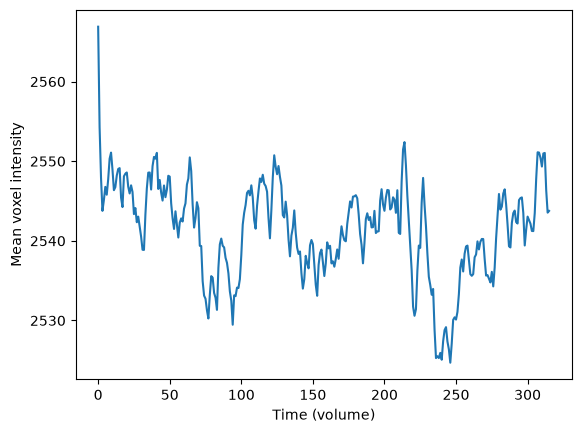

In [10]:
# Header only (data is loaded lazily): shape, voxel size and TR
fmri_img = nib.load(fmri_path)

# Extrating useful data, such as the TR: 
print("Shape (x, y, z, t):", fmri_img.shape, "| voxel size (mm) and TR (s):", fmri_img.header.get_zooms())
tr = fmri_img.header.get_zooms()[-1]
total_volumes = fmri_img.shape[-1]

# Plotting the mean intensity per volume
plt.plot(fmri_img.get_fdata().mean(axis=(0, 1, 2)))
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')
plt.show()

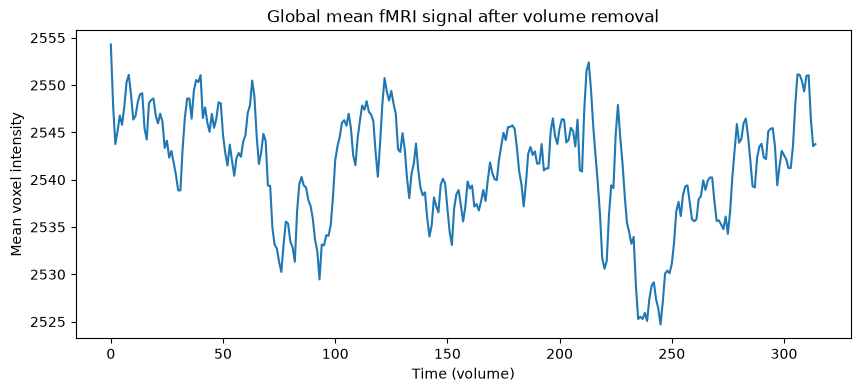

In [13]:
# Defining the output target
settled = op.join(func_dir, "tfMRI_LANGUAGE_LR_settled.nii.gz")

# In order to crop in time, we keep everything from start_vol on. 
# Empirically (from the cella bove) the starting volume is: 
start_vol = 1

# Therefore, we want to keep total_volumes - start_vol:
# fslroi creates new nifti with trimmed number of volumes
fslroi(fmri_path, settled, str(start_vol), str(total_volumes - start_vol))

# Mean voxel intensity after removing the first volume
settled_img = nib.load(settled)
mean_signal_settled = settled_img.get_fdata().mean(axis=(0, 1, 2))

plt.figure(figsize=(10, 4))
plt.plot(mean_signal_settled)
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')
plt.title("Global mean fMRI signal after volume removal")
plt.show()

Processed data will be saved as /home/jovyan/data/tsclient/Projects/Project_1/outputs/func/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [157] to 8 mm pixels
Registering volumes ... [158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298

refnum = 157
Original_refvol = -1


Registering volumes ... [158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][307][308][309][310][311][312][313][314][156][155][154][153][152][151][150][149][148][147][146][145][144][143][142][141][140][139][138][137][136][135][134][133][132][131][130][129][128][127][126][125][124][123][122][121][120][119][

Motion correction completed
Motion parameters shape: (315, 6)
     Rotation x  Rotation y  Rotation z  Translation x  Translation y  \
0      0.000163    0.000492   -0.000059       0.030005      -0.038251   
1     -0.000031    0.000411   -0.001100       0.012959      -0.025233   
2      0.000297   -0.000309   -0.000091      -0.042305      -0.029215   
3      0.000089   -0.000224   -0.000001      -0.034639      -0.014459   
4      0.000297   -0.000207    0.000030      -0.034579      -0.014456   
..          ...         ...         ...            ...            ...   
310    0.000637    0.000457   -0.000409       0.033171      -0.017516   
311    0.000274    0.000454   -0.000409       0.045505      -0.026485   
312    0.000977    0.000258   -0.000409       0.042573      -0.009193   
313   -0.000272    0.000792   -0.000409       0.041113       0.025147   
314    0.000725    0.000506    0.000000       0.040874      -0.013334   

     Translation z  
0         0.059965  
1         0.051918 

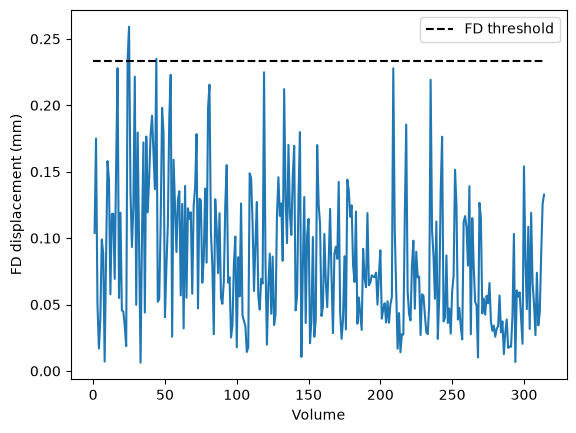

Mean FD 0.085 mm | max 0.259 mm | threshold 0.234 mm | above: [24, 25, 44]


In [14]:
# Defining the output of the motion-corrected images
moco = op.join(func_dir, "tfMRI_LANGUAGE_LR_moco")

# Rigid-body (6 dof) realignment of every volume to the middle volume
mcflirt(infile=settled, o=moco, plots=True, report=True, dof=6, mats=True)

print("Motion correction completed")

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(settled)
fsleyesDisplay.load(moco)

# Creating the .par file with motion parameters: 3 rotations (rad) + 3 translations (mm), one row per volume
mot_params = pd.read_csv(moco + '.par', sep='  ', header=None, engine='python',
                         names=['Rotation x', 'Rotation y', 'Rotation z', 'Translation x', 'Translation y', 'Translation z'])
print("Motion parameters shape:", mot_params.shape)
print(mot_params)

# Compute Power framewise displacement (FD).
# FD measures frame-to-frame head movement using all six motion parameters estimated by MCFLIRT.
# Rotations are converted from radians to millimetres assuming a spherical head radius of 50 mm.

# Difference between consecutive volumes
framewise_diff = mot_params.diff().iloc[1:]
# Rotational displacement (radiants) are converted to equivalent displacement (mm)
converted_rots = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']] * 50
# The total displacement (mm) is:
trans_params   = framewise_diff[['Translation x', 'Translation y', 'Translation z']]
# Sum of absolute rotational and translational differences
fd = (converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)).to_numpy()


# Data-driven outlier threshold: Q3 + 1.5 * IQR
# Identify unusually high motion:
threshold = np.quantile(fd, 0.75) + 1.5*(np.quantile(fd, 0.75) - np.quantile(fd, 0.25))
# np.where(fd > threshold)[0] find the indices of FD values exceeding the threshold
# FD[0] corresponds to the movement between volumes 0 and 1 of the trimmed fMRI series.
# Therefore, +1 gives the index of the later volume.
outliers  = np.where(fd > threshold)[0] + 1

# Report figure: FD over time with the threshold
plt.plot(range(1, fd.size + 1), fd)
plt.hlines(threshold, 0, fd.size, colors='black', linestyles='dashed', label='FD threshold')
plt.xlabel('Volume'); plt.ylabel('FD displacement (mm)'); plt.legend(); plt.show()
print(f"Mean FD {fd.mean():.3f} mm | max {fd.max():.3f} mm | threshold {threshold:.3f} mm | above: {outliers.tolist()}")

# Save for censoring in the GLM
np.savetxt(op.join(func_dir, "fd_outliers.txt"), outliers, fmt="%d")

## 2b. Gaussian smoothing

In [15]:
# 6 mm FWHM (about 3x the 2 mm voxel); fslmaths takes sigma = FWHM / 2.3548
smoothed = moco + "_smoothed-6mm"
fwhm = 6.0
sigma = fwhm/2.3548
subprocess.run(['fslmaths', moco, '-s', str(sigma), smoothed], check=True)

print("Smoothing completed")
print("FWHM:", fwhm, "mm")
print("Sigma:", round(sigma, 3), "mm")

# Report figure: the same volume before and after smoothing
vol = 100
fslroi(moco, moco + "_vol100", str(vol), str(1))
fslroi(smoothed, smoothed + "_vol100", str(vol), str(1))
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(moco + "_vol100")
fsleyesDisplay.load(smoothed + "_vol100")

Smoothing completed
FWHM: 6.0 mm
Sigma: 2.548 mm


# 3. GLM
The goal of the GLM is to investigate the activation of the brain in the math and story tasks.

a) Build an appropriate experimental design matrix that you will use in the following GLM analysis.

b) Compute and plot the correlation matrix between the regressors of the design matrix and comment on the results.

c) Run the GLM at the level you deem reasonable and report the statistical maps of each of the task-related regressors. Briefly comment on the statistical maps.

d) Using the results of the GLM analysis and a contrast vector of your choice, create the activation maps corresponding to the story vs math
contrast. Please include in the report the contrast vector used and the contrast map you obtained.

e) Discuss which brain regions and networks are more activated during numerical than semantic processing, and which are more activated in the opposite contrast. As brain activity at rest can be separated into known functional networks [2], comment the results in terms of functional networks. Report known functional networks found within the statistical results and brain activation maps. You can either observe their overlaps or use brain atlas to inform your answer.

f) [Hard] Based on the literature, some regions should stand out as particularly relevant to semantic language processing. Are these regions present in your contrast maps? If not, discuss at least two possible reasons that could explain their absence.

## Loading data
The GLM needs one time series per voxel, since the preprocessed data is already 4D:

In [26]:
from nilearn.glm.first_level import FirstLevelModel
from nilearn.glm.first_level.design_matrix import _make_drift
from nilearn.glm import threshold_stats_img
from nilearn.plotting import plot_design_matrix, plot_contrast_matrix, plot_stat_map
from nilearn.image import mean_img

# Preprocessed 4D data: volume removed, motion-corrected, smoothed
fmri_img = nib.load(smoothed + ".nii.gz")

# Numer of volumes after the preprocessing:
n_scans = fmri_img.shape[-1]

# Acquisition time of each volume of the trimmed series: 0, TR, 2TR, ...
frame_times = np.arange(n_scans) * tr

Regarding the events, Nilearn needs a DataFrame with exactly three columns: onset (s), duration (s) and trial_type. Each unique trial_type becomes one regressor. 

In [27]:
# Defining the path of the events
events_path = os.path.join(data_dir, 'fMRI', 'tfMRI_LANGUAGE_LR', 'tfMRI_LANGUAGE_LR_task_onsets.csv')

# Reading and printing the events
events = pd.read_csv(events_path)

# DOVREMMO SELEZIONARE GLI EVENTI??
# Keep only the task blocks: sub-events (present/question/response) are
# contained in the blocks and would create near-identical regressors
# events = events[events['trial_type'].isin(['story', 'math'])].copy()

# Since we removed "total_volumes - start_vol" volumes, the "t = 0" shifted, therefore 
# we need to shift all the onsets: 
events['onset'] = events['onset'] - start_vol * tr
events

,onset,duration,trial_type
0,-0.479,28.270,story
1,-0.479,20.445,present_story
2,20.472,1.161,question_story
3,24.830,2.961,response_story
4,27.976,0.727,cue
5,29.375,5.667,present_math
6,29.375,12.241,math
7,35.226,3.391,question_math
8,38.651,2.965,response_math
9,41.850,5.453,present_math


## 3a. Building the design matrix
In order to build the GLM, first of all we need to specify EXPLAIN

We decided to add the following regressors: 
- Signal drift (slow scanner or physiological trends, modelled as low-order polynomials or cosines)
- Censoring (explain what it is)
- Motion parameters

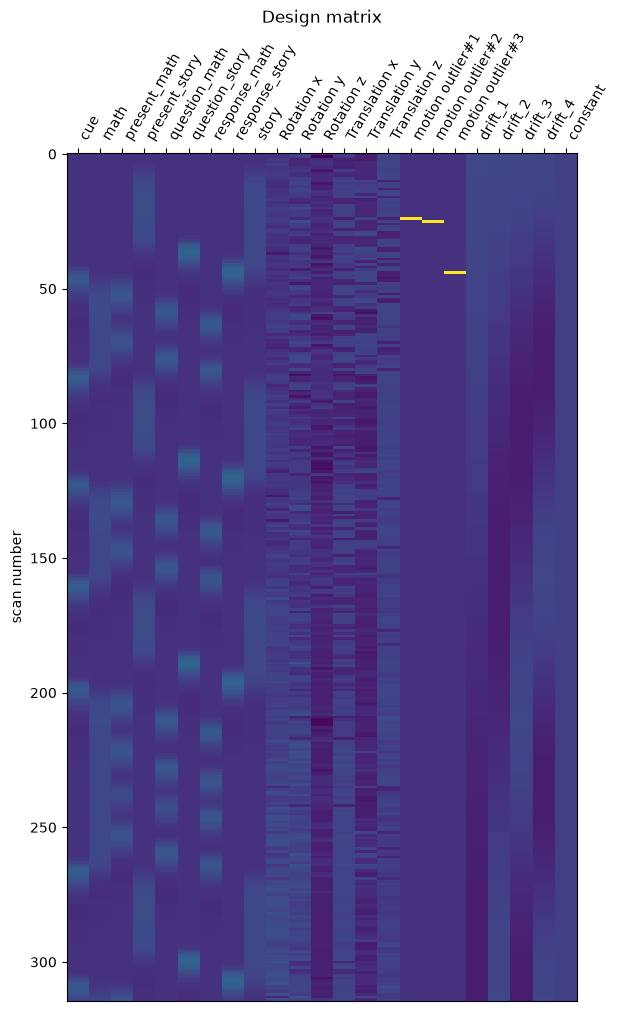

In [30]:
# Defining the regressors: 6 motion parameters from MCFLIRT
# Chek there is exacly one line per volume
assert len(mot_params) == n_scans   
# Define the confounds as the motion paramters, in order to add other regressors later on
confounds = mot_params.copy()


# Defining the regressors: censoring
# One "spike" regressor per FD outlier (1 on that volume, 0 elsewhere) is added
for i, v in enumerate(outliers):
    reg = np.zeros((n_scans,))
    reg[v] = 1.0
    confounds['motion outlier#' + str(i+1)] = reg


# Defining the design matrix (DOBBIAMO SCEGLIERE COME MODELLARE IL DRIFT)
design_mat = make_first_level_design_matrix(frame_times,
                                            events,
                                            hrf_model='spm',
                                            drift_model='cosine',
                                            high_pass=.01,
                                            add_regs=confounds.values,
                                            add_reg_names=list(confounds.columns))

plot_design_matrix(design_mat)
plt.title('Design matrix')
plt.show()

In [3]:
# cell needed for GLM <-> PCA alignment

import json
from pathlib import Path

shared_dir = Path.home() / "NSSP_outputs" / "shared_glm_pca"
shared_dir.mkdir(parents=True, exist_ok=True)


preprocessed_path = Path(smoothed)
if not str(preprocessed_path).endswith((".nii", ".nii.gz")):
    preprocessed_path = Path(str(preprocessed_path) + ".nii.gz")

preprocessed_path = preprocessed_path.resolve(strict=True)
export_img = nib.load(preprocessed_path)

assert len(design_mat) == export_img.shape[-1]
assert np.allclose(
    design_mat.index.to_numpy(dtype=float),
    np.arange(len(design_mat)) * tr,
    rtol=0,
    atol=1e-5,
)

design_mat.to_csv(
    shared_dir / "design_matrix.csv",
    index_label="frame_time_s",
)

metadata = {
    "fmri_path": str(preprocessed_path),
    "tr_s": float(tr),
    "start_vol": int(start_vol),
    "n_scans": int(export_img.shape[-1]),
    "columns": list(design_mat.columns),
    "task_regressors": sorted(events["trial_type"].unique().tolist()),
}

(shared_dir / "metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("File condivisi salvati in:", shared_dir)

NameError: name 'smoothed' is not defined

## 3b. Correlation between regressors

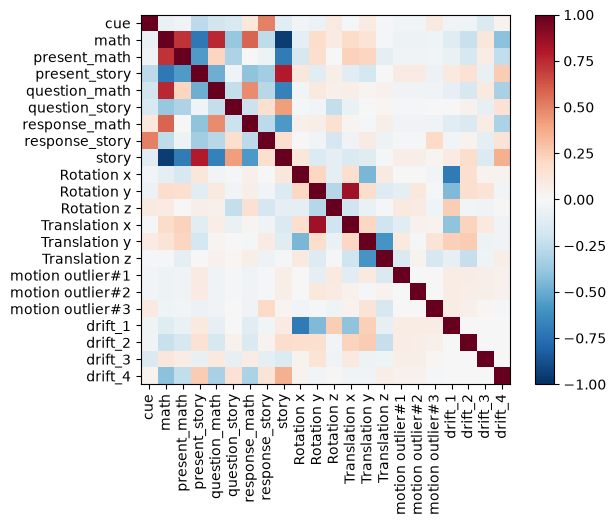

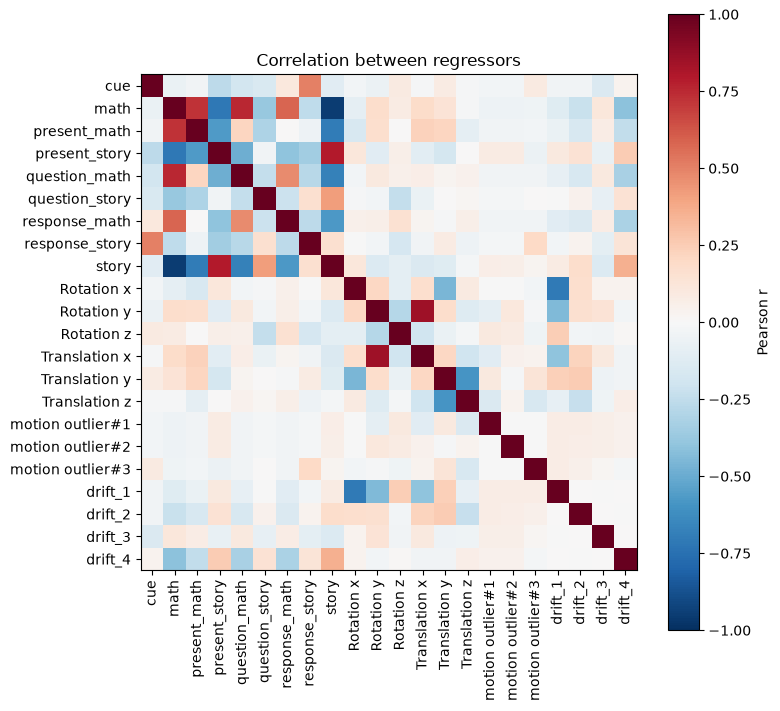

In [35]:
cols = [c for c in design_mat.columns if c != 'constant'] # the constant has zero variance → NaN correlations 
corr = design_mat[cols].corr()

plt.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r'); 
plt.colorbar(); 
plt.xticks(range(len(cols)), cols, rotation=90); 
plt.yticks(range(len(cols)), cols); 
plt.show() 

# Per il plot Claude mi ha suggerito: 
plt.figure(figsize=(8, 8))
plt.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar(label='Pearson r')
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title('Correlation between regressors')
plt.show()

## 3c. Fitting the model
Since there is only one subject, we need to condutc a first level analysis. 

In [ ]:
from nilearn.glm.first_level import FirstLevelModel

# DA DECIDERE CHE TIPI DI DRIFTING REGRESSORS SONO IDEALI DA UTILIZZARE QUA, IL LAB USA POLINOMIALI

#from nilearn.glm.first_level.design_matrix import _make_drift
#column_values, column_names = _make_drift(drift_model='polynomial',
#                           frame_times=np.asarray(list(range(0, 666, 7))),  # 96 scans × TR 7 s
#                                          order=3, high_pass=None)


# Define what type of GLM we want (nature of the noise, repetition time of the data...)
# The function creates an empty model object that still needs to be fitted
# DA CAPIRE QUALI PARAMETRI SI TENGONO E QUALI NO
fmri_glm = FirstLevelModel(t_r=tr,          # repetition time: tells nilearn when each scan was acquired
			         noise_model='ar1',     # AR(1) pre-whitening for autocorrelated noise
			         standardize=False,     # keep signal units (betas in original scale)
			         hrf_model='spm',       # canonical double-gamma HRF used for convolution
			         drift_model='cosine',  # automatically adding cosine drft regressors
			         high_pass=.01)         # cutoff (Hz) — only used by the 'cosine' drift model, so ignored here

# Cancellare righe sopra??
fit_glm = FirstLevelModel(t_r=7.0, drift_model='None', minimize_memory=False) 
fit_glm.fit(fmri_img, design_matrices=[design_mat])

# Manca la statistical maps of each of the task-related regressors.

## 3d. Contrast and activation maps activation "story vs math"